# 03 · Feature Engineering

The EDA showed that a single reading cannot always tell the **hair straightener** from the **100 W bulb**, but the
**history** can (surge at switch-on, decaying power, slightly lower power factor). This notebook builds features that
capture that history and checks which ones actually help.

**Rules for every feature**

1. **Causal:** a feature at time *t* uses only samples up to *t*, so it can be computed live, as data arrives.
2. **One implementation for training and real time:** all features are computed by
   `src/features.py → features_from_window()`, which only sees the last 120 samples (10 minutes). Offline the window
   slides over each recording; live it is a buffer of the latest readings (`StreamingFeatureBuilder`).
3. **Appliance properties only:** power, current, power factor. No voltage, frequency, energy or counter.

1 sample = 5 seconds (the resolution of the dataset). The live 1-second stream will be reduced to the same 5-second
grid before features are computed.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path.cwd().parent))
from src.config import APPLIANCES, APPLIANCE_NAMES, FIGURES_DIR, DATA_PROCESSED, RANDOM_STATE
from src.data_loader import load_labelled
from src.features import (build_features, StreamingFeatureBuilder, FEATURE_SETS, ALL_FEATURES,
                          BASE, INSTANT, ROLLING, EVENT, WINDOW, STEP_THRESHOLD_W)
from src.evaluation import cross_val_predict_labels, score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIGURES_DIR / f"{name}.png")

df = load_labelled()
print(df.shape)

(1370, 20)


## 1. Feature definitions

| Group | Feature | Meaning | Why it may help |
|---|---|---|---|
| **Base** | `power_W`, `current_A`, `pf` | The current reading | Total load level |
| **Instant** | `pf_clean` | PF, set to 0 when power < 15 W (PF is pure noise with no load) | Removes noise from the "all off" state |
| | `current_net_A` | Current minus the 0.098 A sensor offset | True load current |
| | `q_est_var` | Estimated reactive power = P · tan(arccos PF) | Bulbs and dryer ≈ 0; the straightener adds some |
| **Rolling** | `dP_1`, `dP_2` | Power change vs 1 and 2 samples ago (5 s, 10 s) | Detects a switch happening now |
| | `P_mean_k`, `P_std_k` (k = 3, 6, 12) | Mean / std of power over the last 15 s, 30 s, 60 s | Stability: bulbs are flat, the straightener drifts |
| | `P_min_12`, `P_max_12` | Min / max power in the last 60 s | Recent surges |
| | `P_slope_6` | Linear trend of power over the last 30 s (W per sample) | Straightener heating ⇒ falling power |
| | `pf_mean_6` | Mean clean PF over the last 30 s | Smoothed PF (less noisy) |
| **Event memory** | `last_up_step_W` | Size of the most recent upward switch (level 10 s after it minus level before) | *Which* appliance switched on last |
| | `last_up_surge_W` | First-sample jump minus the settled step | Straightener surge vs clean bulb step |
| | `last_up_pf_change` | PF change caused by that switch | Straightener lowers PF |
| | `samples_since_up` | Samples since that switch (max 120) | How old the information is |
| | `post_up_drift_W` | Power change since just after that switch | Straightener keeps drifting down |
| | `last_down_step_W`, `samples_since_down` | The same for the most recent downward switch | Which appliance switched off |

A *switch* is a change of more than 40 W between two consecutive samples.

In [2]:
F = build_features(df)
data = pd.concat([df, F.drop(columns=BASE)], axis=1)
print(f"Feature matrix: {F.shape[0]} rows x {F.shape[1]} features")
data[["source_file", "counter", "combo"] + ALL_FEATURES].iloc[600:610]

Feature matrix: 1370 rows x 25 features


,source_file,counter,combo,power_W,current_A,pf,pf_clean,current_net_A,q_est_var,dP_1,...,P_max_12,P_slope_6,pf_mean_6,last_up_step_W,last_up_surge_W,last_up_pf_change,samples_since_up,post_up_drift_W,last_down_step_W,samples_since_down
600,pause.log,3935,0000,2.1,0.098,0.088,0.0,0.00,0.0,4.4,...,2.1,0.251429,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
601,pause.log,3940,0000,2.8,0.098,0.114,0.0,0.00,0.0,0.7,...,2.8,0.477143,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
602,pause.log,3945,0000,0.4,0.098,0.016,0.0,0.00,0.0,-2.4,...,2.8,0.554286,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
603,pause.log,3950,0000,1.2,0.098,0.051,0.0,0.00,0.0,0.8,...,2.8,0.522857,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
604,pause.log,3955,0000,-0.5,0.098,-0.017,0.0,0.00,0.0,-1.7,...,2.8,0.111429,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
605,pause.log,3960,0000,1.9,0.118,0.078,0.0,0.02,0.0,2.4,...,2.8,-0.288571,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
606,pause.log,3965,0000,1.1,0.098,0.045,0.0,0.00,0.0,-0.8,...,2.8,-0.162857,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
607,pause.log,3970,0000,0.7,0.118,0.029,0.0,0.02,0.0,-0.4,...,2.8,0.102857,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
608,pause.log,3975,0000,-1.6,0.098,-0.067,0.0,0.00,0.0,-2.3,...,2.8,-0.320000,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0
609,pause.log,3980,0000,0.8,0.118,0.034,0.0,0.02,0.0,2.4,...,2.8,-0.125714,0.0,0.0,0.0,0.0,120.0,0.0,0.0,120.0


In [3]:
F.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
power_W,1370.0,556.51,707.87,-3.60,2.85,162.10,1479.30,2392.90
current_A,1370.0,2.31,2.88,0.08,0.12,0.67,6.05,10.45
pf,1370.0,0.74,0.43,-0.15,0.12,0.99,1.00,1.00
pf_clean,1370.0,0.73,0.43,0.00,0.00,0.99,1.00,1.00
current_net_A,1370.0,2.21,2.88,0.00,0.02,0.57,5.96,10.35
q_est_var,1370.0,32.85,68.06,0.00,0.00,0.00,34.93,850.50
dP_1,1370.0,-0.28,245.72,-1511.30,-3.90,-0.60,2.10,1556.50
dP_2,1370.0,-0.55,339.97,-1512.30,-6.98,-0.80,2.30,1559.50
P_mean_3,1370.0,556.84,688.85,-1.87,85.11,178.10,1007.05,2142.20
P_std_3,1370.0,53.20,153.08,0.00,1.07,2.41,13.93,734.45


## 2. Check: streaming features == offline features

The real-time service will feed readings one by one into `StreamingFeatureBuilder`. Replaying the test log through
it must give exactly the same features as the offline computation.

In [4]:
g = df[df.source_file == "testingdataset.log"]
builder = StreamingFeatureBuilder()
stream = pd.DataFrame([builder.push(p, i, pf) for p, i, pf in g[["power_W", "current_A", "pf"]].to_numpy()],
                      index=g.index)
max_diff = (stream[ALL_FEATURES] - F.loc[g.index, ALL_FEATURES]).abs().max().max()
print(f"Samples replayed: {len(g)}   max |stream - offline| over all features: {max_diff}")
assert max_diff == 0

Samples replayed: 183   max |stream - offline| over all features: 0.0


## 3. What the history features look like

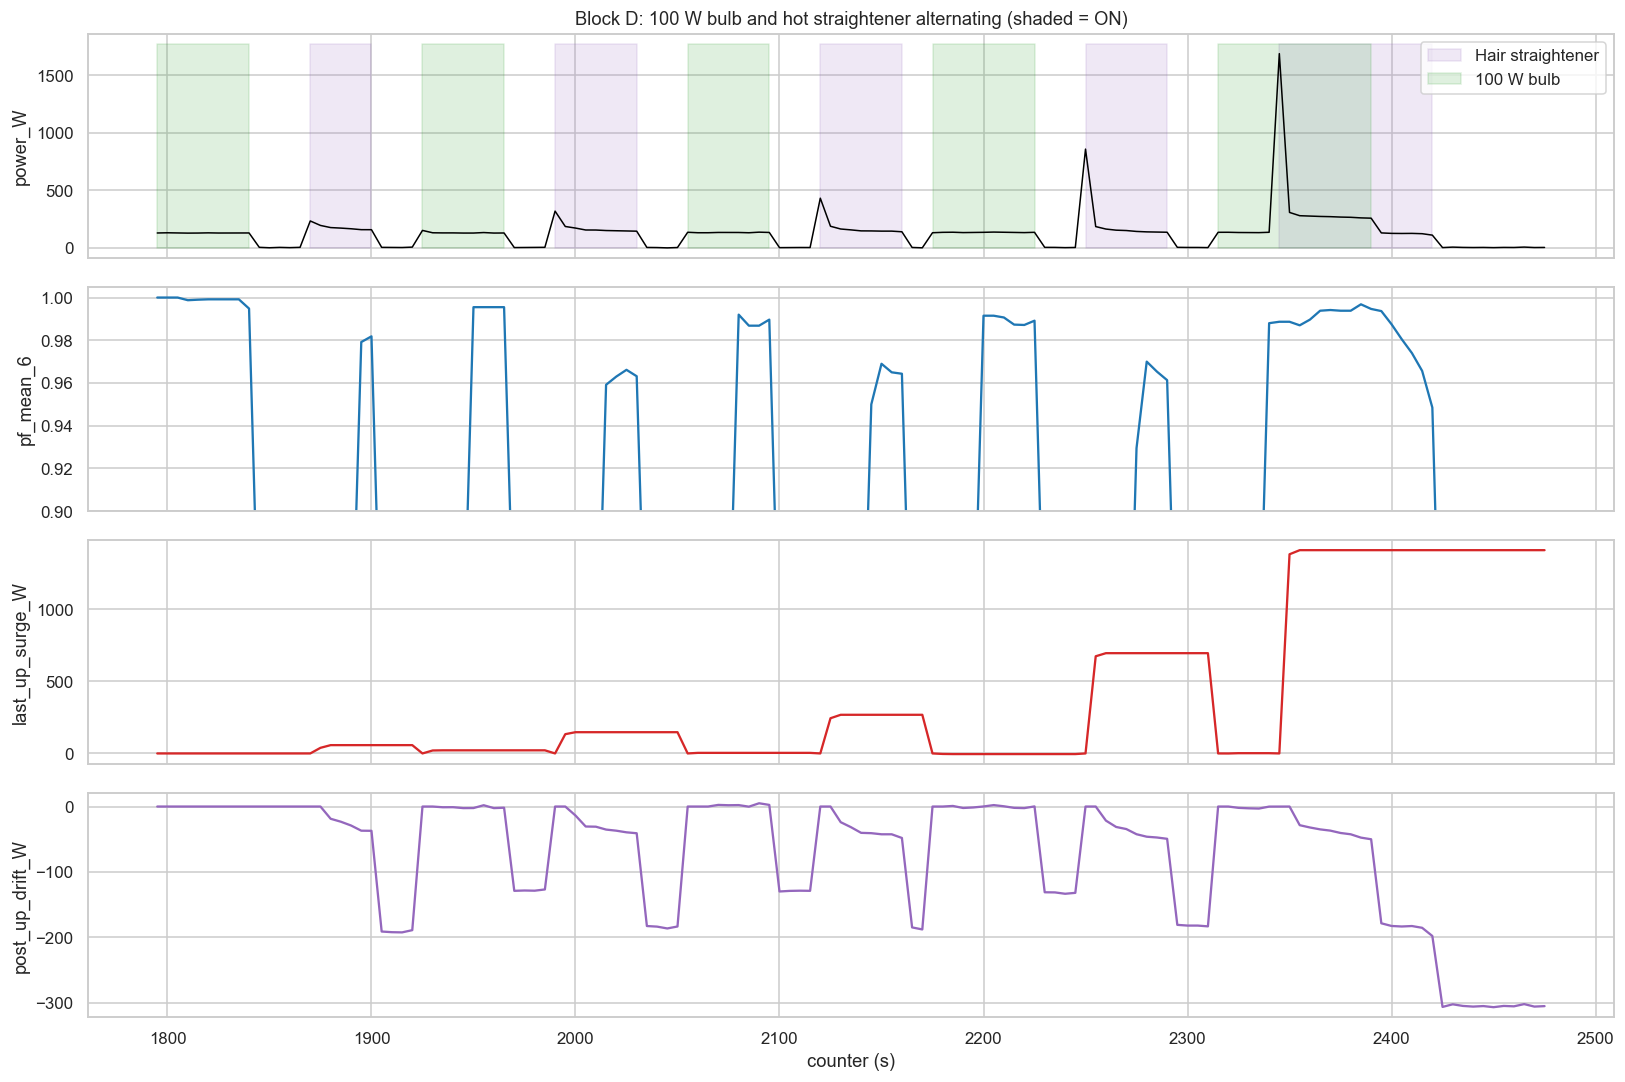

In [5]:
blk = data[data.block == "D_lookalike"]
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
axes[0].plot(blk.counter, blk.power_W, color="black", lw=1)
for a, c in [("hair_straightener", "#9467bd"), ("bulb_100W", "#2ca02c")]:
    axes[0].fill_between(blk.counter, 0, blk.power_W.max() * 1.05, where=blk[a] == 1, color=c, alpha=0.15,
                         step="mid", label=APPLIANCE_NAMES[a])
axes[0].set_ylabel("power_W"); axes[0].legend(loc="upper right")
axes[0].set_title("Block D: 100 W bulb and hot straightener alternating (shaded = ON)")
axes[1].plot(blk.counter, blk.pf_mean_6, color="tab:blue"); axes[1].set_ylabel("pf_mean_6"); axes[1].set_ylim(0.9, 1.005)
axes[2].plot(blk.counter, blk.last_up_surge_W, color="tab:red"); axes[2].set_ylabel("last_up_surge_W")
axes[3].plot(blk.counter, blk.post_up_drift_W, color="tab:purple"); axes[3].set_ylabel("post_up_drift_W")
axes[3].set_xlabel("counter (s)")
fig.tight_layout(); save(fig, "15_history_features_lookalike"); plt.show()

While the two appliances draw almost the same power, the history features differ: when the straightener is the one
that switched on, `last_up_surge_W` is high, `post_up_drift_W` is negative (power keeps falling), and the smoothed
PF is lower (≈ 0.96 vs ≈ 0.99–1.00).

There is also a visible weakness: the event-memory values **persist after the appliance switches off** (e.g.
`last_up_surge_W` stays high until the next upward switch, and `post_up_drift_W` jumps when power drops). A plain
feature cannot tell "the straightener switched on and is still on" from "it switched on and has since switched off".
Section 7 shows what this does to a classifier.

## 4. Which features separate the hard pair?

Rows where exactly one of {straightener, 100 W bulb} is ON (any state of the other appliances). For each feature,
the ROC-AUC of using it alone to say "it is the straightener" (0.5 = useless, 1.0 = perfect; shown as
max(AUC, 1 − AUC) so the direction does not matter).

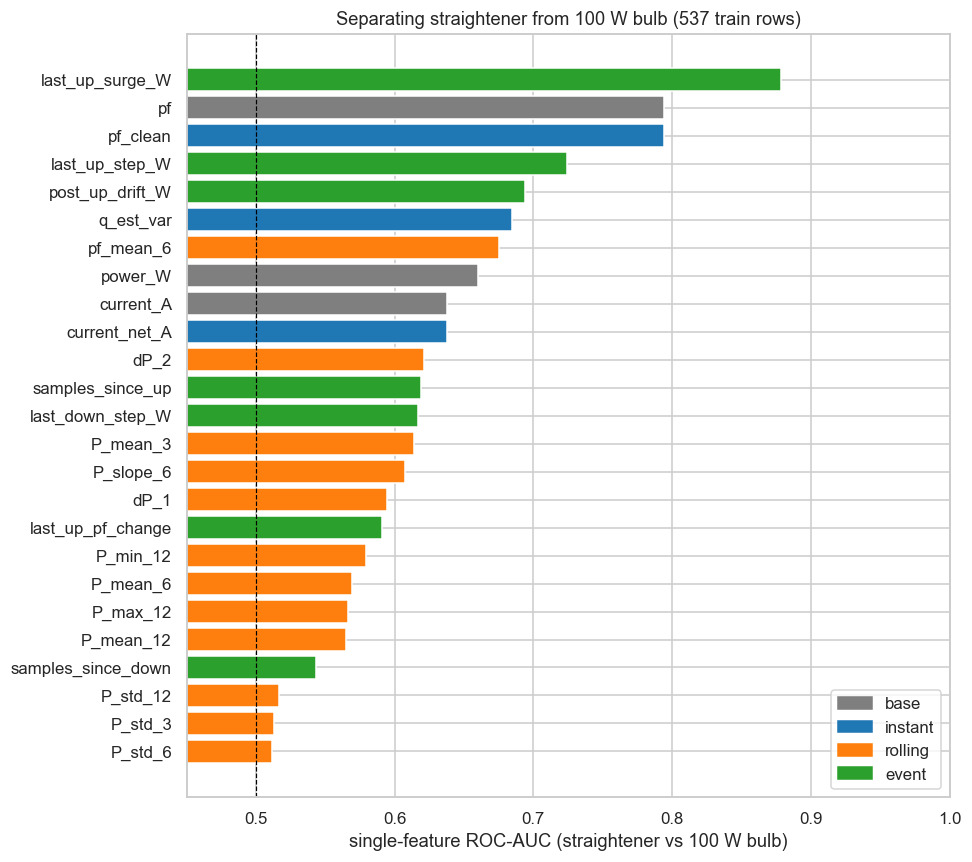

,AUC
last_up_surge_W,0.878
pf_clean,0.794
pf,0.794
last_up_step_W,0.724
post_up_drift_W,0.694
q_est_var,0.685
pf_mean_6,0.675
power_W,0.660
current_A,0.638
current_net_A,0.638


In [6]:
train = data[data.split == "train"]
hard = train[(train.hair_straightener + train.bulb_100W) == 1]
y_hard = hard.hair_straightener.values
auc = {}
for f in ALL_FEATURES:
    a = roc_auc_score(y_hard, hard[f].values)
    auc[f] = max(a, 1 - a)
auc = pd.Series(auc).sort_values()
group_of = {**{f: "base" for f in BASE}, **{f: "instant" for f in INSTANT},
            **{f: "rolling" for f in ROLLING}, **{f: "event" for f in EVENT}}
pal = {"base": "#7f7f7f", "instant": "#1f77b4", "rolling": "#ff7f0e", "event": "#2ca02c"}

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(auc.index, auc.values, color=[pal[group_of[f]] for f in auc.index])
ax.axvline(0.5, color="black", lw=0.8, ls="--")
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("single-feature ROC-AUC (straightener vs 100 W bulb)")
ax.set_title(f"Separating straightener from 100 W bulb ({len(hard)} train rows)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal.keys()), loc="lower right")
fig.tight_layout(); save(fig, "16_hard_pair_auc"); plt.show()
auc.sort_values(ascending=False).head(10).round(3).to_frame("AUC")

## 5. Mutual information with each appliance

Mutual information measures how much knowing a feature reduces uncertainty about an appliance's state (higher is
better, captures non-linear relations).

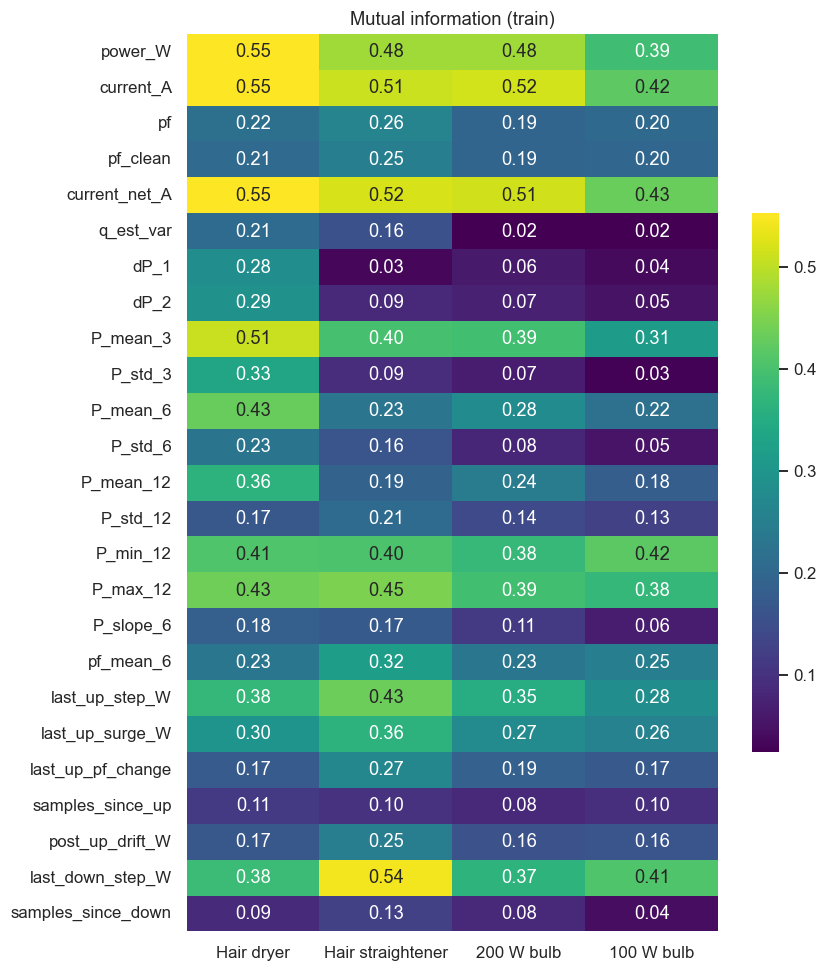

In [7]:
mi = pd.DataFrame({APPLIANCE_NAMES[a]: mutual_info_classif(train[ALL_FEATURES], train[a], random_state=RANDOM_STATE)
                   for a in APPLIANCES}, index=ALL_FEATURES)
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(mi, annot=True, fmt=".2f", cmap="viridis", ax=ax, cbar_kws={"shrink": 0.6})
ax.set_title("Mutual information (train)")
fig.tight_layout(); save(fig, "17_mutual_information"); plt.show()

The **dryer** is explained by almost any power feature. For the **straightener** and the **100 W bulb**, power factor
and the event-memory features carry information that the base power level does not.

## 6. Redundancy between features

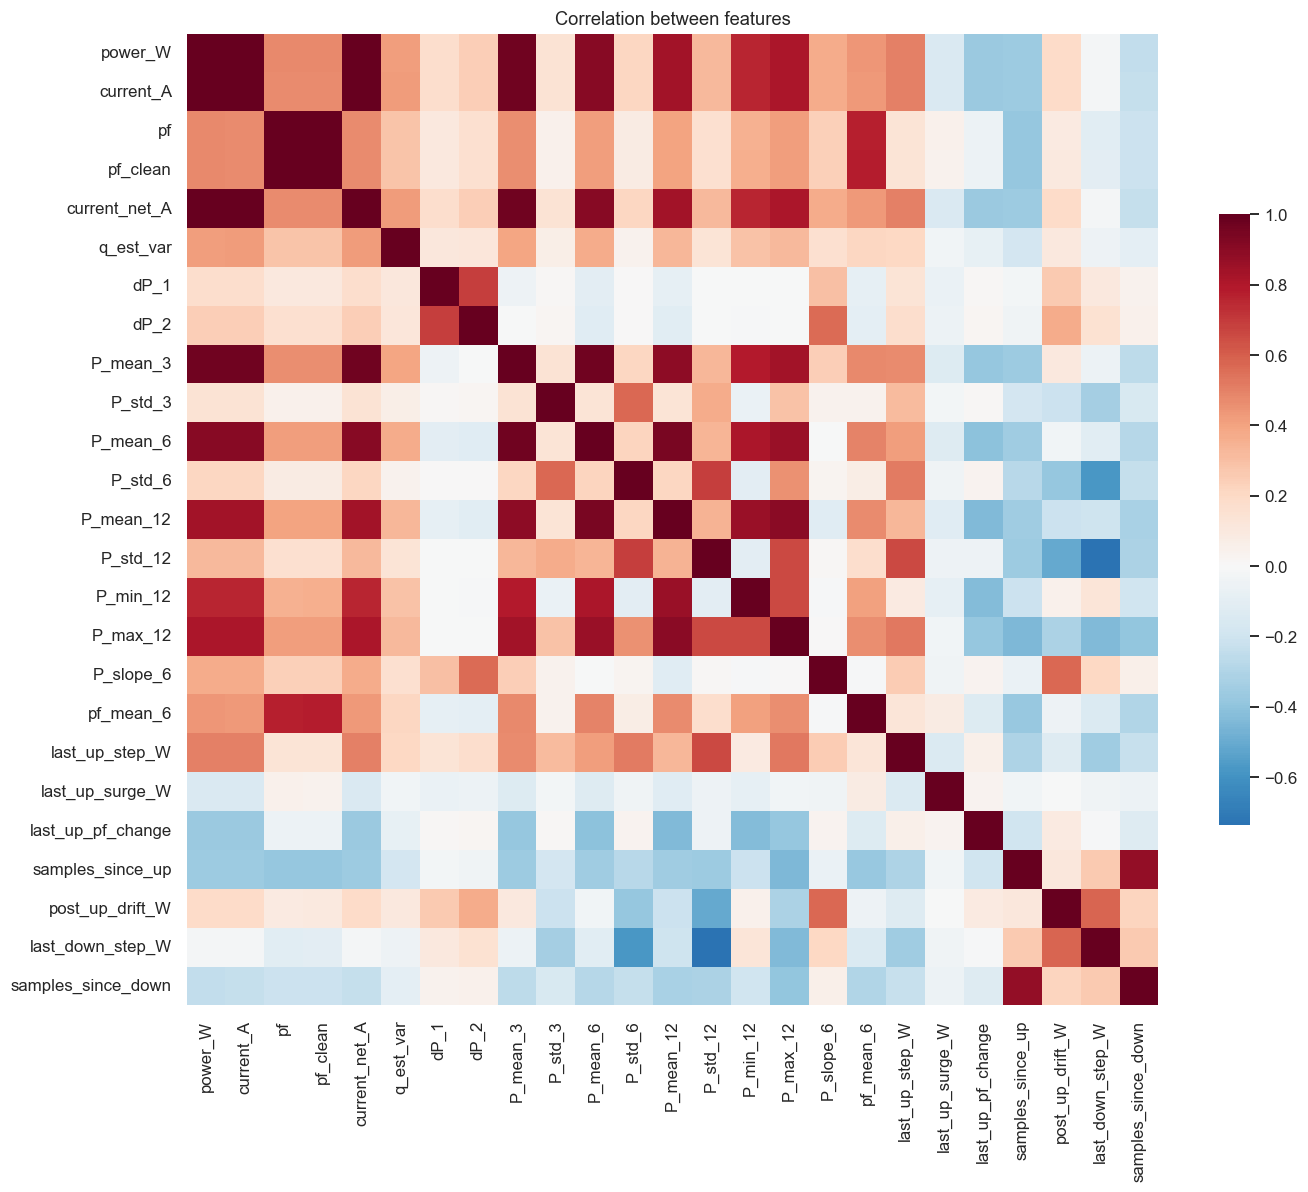

In [8]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(train[ALL_FEATURES].corr(), cmap="RdBu_r", center=0, ax=ax, square=True, cbar_kws={"shrink": 0.6})
ax.set_title("Correlation between features")
fig.tight_layout(); save(fig, "18_feature_correlation"); plt.show()

The power-level features (`power_W`, `current_A`, `current_net_A`, rolling means, min/max) are strongly correlated:
they all describe the load level. Tree models handle this redundancy well; linear models and k-NN need scaling and
may benefit from the smaller feature sets.

## 7. Feature-set ablation

How much does each group of features add? A fixed Random Forest (no tuning yet) is evaluated with
**leave-one-block-out cross-validation on the training blocks only** (the test block stays untouched until the final
comparison). Two ways of framing the target are compared:

- **combo**: one 16-class prediction (which of the 16 on/off combinations);
- **multilabel**: four separate yes/no predictions, one per appliance.

Feature sets: `snapshot` (3), `snapshot_plus` (6), `compact_history` (9: + `pf_mean_6`, `P_std_3`, `dP_1`),
`rolling` (18), `full` (25).

In [9]:
X_all = train[ALL_FEATURES].reset_index(drop=True)
y = train[APPLIANCES].to_numpy()
groups = train["block"].astype(str).to_numpy()
rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)

rows = []
oof = {}
for name, cols in FEATURE_SETS.items():
    for target in ["combo", "multilabel"]:
        pred = cross_val_predict_labels(rf, X_all[cols], y, groups, fit_target=target)
        if target == "combo":
            oof[name] = pred
        rows.append({"feature_set": name, "target": target, "n_features": len(cols), **score(y, pred)})
ablation_all = pd.DataFrame(rows)
ablation_all[["feature_set", "target", "n_features", "exact_match", "macro_f1", "acc_hair_dryer",
              "acc_hair_straightener", "acc_bulb_200W", "acc_bulb_100W"]].round(3)

,feature_set,target,n_features,exact_match,macro_f1,acc_hair_dryer,acc_hair_straightener,acc_bulb_200W,acc_bulb_100W
0,snapshot,combo,3,0.868,0.883,0.992,0.880,0.956,0.876
1,snapshot,multilabel,3,0.861,0.886,0.992,0.885,0.962,0.872
2,snapshot_plus,combo,6,0.876,0.894,0.992,0.890,0.962,0.885
3,snapshot_plus,multilabel,6,0.872,0.896,0.992,0.895,0.963,0.885
4,compact_history,combo,9,0.877,0.894,0.992,0.888,0.965,0.885
5,compact_history,multilabel,9,0.875,0.899,0.992,0.893,0.967,0.890
6,rolling,combo,18,0.799,0.836,0.992,0.819,0.952,0.815
7,rolling,multilabel,18,0.774,0.841,0.992,0.826,0.949,0.825
8,full,combo,25,0.777,0.817,0.992,0.794,0.946,0.798
9,full,multilabel,25,0.750,0.834,0.992,0.809,0.947,0.825


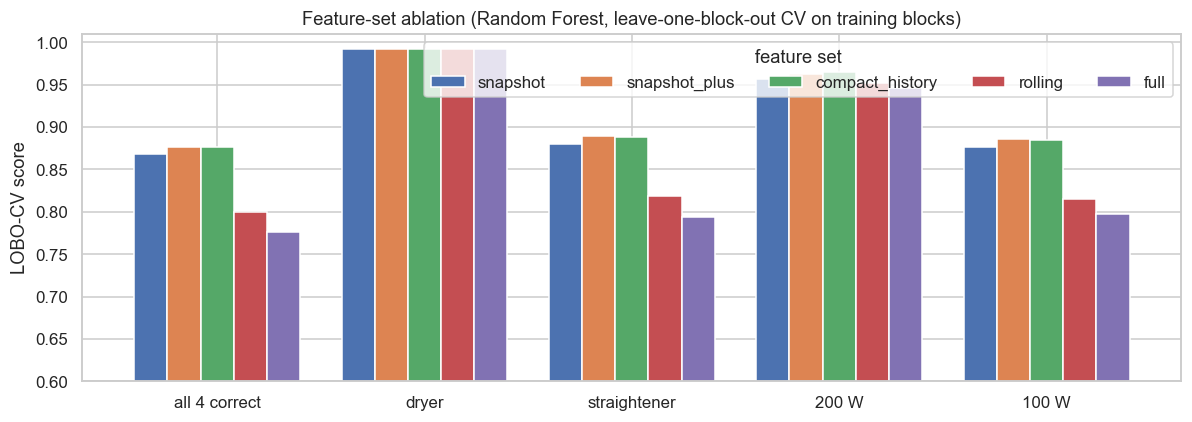

In [10]:
ablation = ablation_all[ablation_all.target == "combo"].set_index("feature_set")
fig, ax = plt.subplots(figsize=(11, 4))
plot_cols = ["exact_match", "acc_hair_dryer", "acc_hair_straightener", "acc_bulb_200W", "acc_bulb_100W"]
ablation[plot_cols].T.plot.bar(ax=ax, rot=0, width=0.8)
ax.set_ylim(0.6, 1.01); ax.set_ylabel("LOBO-CV score")
ax.set_xticklabels(["all 4 correct", "dryer", "straightener", "200 W", "100 W"])
ax.set_title("Feature-set ablation (Random Forest, leave-one-block-out CV on training blocks)")
ax.legend(title="feature set", ncol=5)
fig.tight_layout(); save(fig, "19_feature_ablation"); plt.show()

**A surprising but important result: more history does *not* help this classifier.**

- `snapshot_plus` and `compact_history` are the best (≈ 87–88 % of samples with all 4 appliances correct).
- Adding all rolling features (`rolling`) or the event memory (`full`) **lowers** the cross-validated score to
  ≈ 75–80 %, for both target framings, and the drop is concentrated in the combination tours (table below).

Why, even though the event features separate the hard pair well on their own (section 4)?

1. The 60-second rolling statistics mix several states together: in the tours the appliances switch every 40 s,
   so `P_mean_12`, `P_min_12`, `P_max_12` often describe the *previous* combination.
2. The event memory only describes the **most recent** switch. In the tours that switch is usually a *different*
   appliance than the straightener or the 100 W bulb, so the same feature value means different things in
   different blocks.
3. With only ≈ 32 rows per combination in the tours, the forest uses these features to memorise block-specific
   patterns, which do not transfer to an unseen block.

**Conclusion:** history information is valuable, but it must be used in a structured way: remember *which
appliance* each switch belonged to and keep a state per appliance. That is exactly what the event-based
**Model B** does. For Model A, the compact feature sets are the strongest; all five sets are still compared after
hyper-parameter tuning in notebook 04, because a more regularised model may use the history features better.

In [11]:
per_block = pd.DataFrame({
    name: pd.Series((pred == y).all(axis=1)).groupby(groups).mean()
    for name, pred in oof.items()
}).round(3)
per_block["rows"] = pd.Series(groups).value_counts()
per_block

,snapshot,snapshot_plus,compact_history,rolling,full,rows
A_baseline,1.000,1.000,1.000,1.000,1.000,37
B_single_cycles,0.905,0.895,0.895,0.914,0.936,220
C_straightener,0.950,0.965,0.965,0.835,0.875,200
D_lookalike,0.956,0.949,0.942,0.920,0.956,137
E_tour1,0.648,0.695,0.742,0.609,0.562,128
E_tour2,0.803,0.811,0.826,0.682,0.636,132
E_tour3,0.821,0.836,0.793,0.636,0.521,140
E_tour4,0.822,0.830,0.830,0.763,0.637,135
pause,1.000,1.000,1.000,1.000,1.000,58


## 8. Feature importance (Random Forest, full feature set)

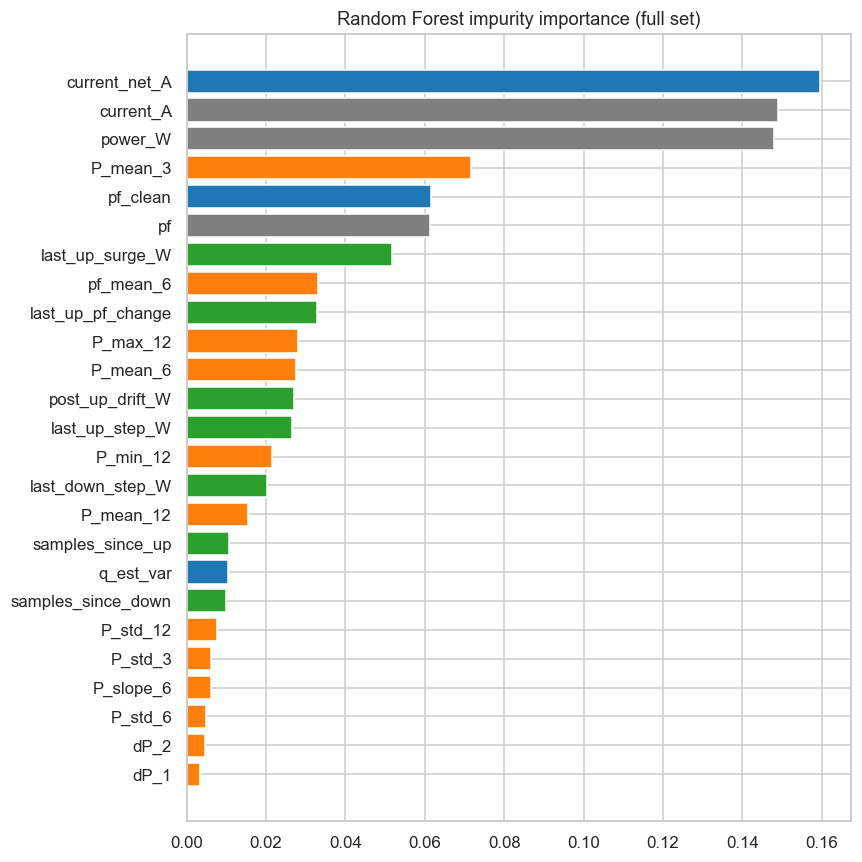

In [12]:
model = rf().fit(X_all, train["combo"].values)
imp = pd.Series(model.feature_importances_, index=ALL_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(imp.index, imp.values, color=[pal[group_of[f]] for f in imp.index])
ax.set_title("Random Forest impurity importance (full set)")
fig.tight_layout(); save(fig, "20_rf_feature_importance"); plt.show()

## 9. Save the feature table

In [13]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
out = DATA_PROCESSED / "features.csv"
data.to_csv(out, index=False)
print("Saved", out.relative_to(Path.cwd().parent), data.shape)

Saved data\processed\features.csv (1370, 42)


## Summary

- **25 causal features** in four groups (base, instant, rolling, event memory), all computed by one function that
  is shared with the real-time service. Streaming and offline features match exactly.
- The **power level alone** separates the dryer and most combinations; the **straightener vs 100 W bulb** pair needs
  power factor and history (surge, drift, recent switch size).
- With an untuned Random Forest, the compact sets (`snapshot_plus`, `compact_history`) score best under
  leave-one-block-out CV (≈ 87–88 % exact match). Long rolling windows and the event memory *reduce* accuracy
  in a snapshot classifier because they describe other appliances' switches and get memorised per block.
- This motivates **Model B**, which uses switch events in a structured way (one state per appliance).
- All five feature sets are carried into the tuned model comparison (notebook 04).

Next: **04 · Model A: snapshot / history classifiers with hyper-parameter tuning**.